# E2. Tiền xử lý, tạo và chọn feature

Đây là bước Data preprocessing của ML pipeline (Bài 04), gồm xử lý giá trị thiếu và ngoại lệ, biến đổi và mã hoá
feature, tạo feature mới và chọn feature. Các lựa chọn xuất phát từ phát hiện ở E1 và được kiểm chứng bằng CV 5 fold
trên `data/folds.csv` theo quy ước ở E0.

> **Trong cuộc thi.** Model LightGBM đầu tiên của nhóm, `A_lgb` (14/10, CV 0,96089), được xây theo kiểu bậc thang:
> mỗi bước thêm một nhóm feature và chỉ giữ bước làm CV tăng (`src/features.py`, chuyển từ code thi). Model Logistic
> Regression `A_lr` (15/10, CV 0,95974) dùng lại các feature đó dưới dạng one-hot thưa. Ngày 18/10 nhóm thử ghép
> thẳng 129 nghìn dòng dữ liệu gốc vào phần train của fold, nhưng chỉ tăng 1×10⁻⁴ (`A_lgb_origrow` 0,959729 so với
> 0,959630). Phần dưới chạy lại hai bậc thang đó trên cùng fold và bổ sung các so sánh theo Bài 04.

Nội dung:
1. Logistic Regression: bậc thang từ baseline E0 tới công thức `A_lr`
2. Các nhánh tiền xử lý trên LR: giá trị thiếu, biến đổi delay, chuẩn hoá
3. Tạo feature theo Bài 04 / 06: tổng hợp điểm, cụm KMeans, PCA
4. Chọn feature: filter, wrapper, embedded
5. LightGBM (chạy trên Kaggle): cùng bậc thang và cùng các nhánh, so với LR
6. Tóm tắt

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent / "src"))

import pickle
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.sparse as sp
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.cluster import KMeans
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.exceptions import ConvergenceWarning
from sklearn.impute import KNNImputer, SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import (FunctionTransformer, MinMaxScaler, OneHotEncoder, RobustScaler,
                                   StandardScaler)

from config import CAT_COLS, DATA_DIR, FEATURES, N_FOLDS, NUM_COLS, OOF_DIR, RESULTS_DIR, SCORE_COLS, TARGET
from cv import compare, log_result, run_cv
from data import load_data
from features import DIGIT_COLS, KEY_PAIRS, add_te, build_static
import plot as P

pd.set_option("display.width", 200)
warnings.filterwarnings("ignore", category=ConvergenceWarning)  # saga 100 vòng (mục 4.3)
train, test = load_data()
y, fold = train[TARGET].values, train["fold"].values
AGE, FD, DEP, ARR = NUM_COLS
EXP = "E2_lr"
OOF_DIR.mkdir(exist_ok=True)


def cached(variant, fn, base=None, notes=""):
    """Chạy fn() -> res (dict của run_cv) rồi ghi results/E2_lr.csv; nếu đã có kết quả và OOF thì đọc lại."""
    path, oof_path = RESULTS_DIR / f"{EXP}.csv", OOF_DIR / f"oof_E2_lr_{variant}.npy"
    if path.exists() and oof_path.exists() and variant in set(pd.read_csv(path)["variant"]):
        oof = np.load(oof_path)
        row = pd.read_csv(path).set_index("variant").loc[variant]
        res = {"oof": oof, "fold_auc": [roc_auc_score(y[fold == k], oof[fold == k]) for k in range(N_FOLDS)],
               "cv_auc": roc_auc_score(y, oof), "seconds": row["seconds"]}
    else:
        res = fn()
        np.save(oof_path, res["oof"])
        if penalty_note := res.get("nonzero"):
            notes = f"{notes} hệ số khác 0 (fold cuối): {penalty_note}/{res['n_features']}".strip()
    if not notes and path.exists() and variant in set(pd.read_csv(path)["variant"]):
        old = pd.read_csv(path).set_index("variant").loc[variant, "notes"]
        notes = old if isinstance(old, str) else ""
    log_result(EXP, variant, res, base=base, notes=notes)
    c = f"  Δ {compare(base, res)['delta_cv']:+.6f} ({compare(base, res)['folds_up']}/5 fold tăng)" if base else ""
    print(f"{variant:32s} CV {res['cv_auc']:.6f}{c}")
    return res

## 1. Logistic Regression: bậc thang feature
LR là model tuyến tính, mỗi feature chỉ đóng góp qua một hệ số. Vì vậy các quan hệ phi tuyến, các tương tác và
trường hợp điểm 0 (E1) đều phải được mã hoá sẵn thành feature, và tiền xử lý ảnh hưởng tới LR nhiều hơn tới model
cây.

Các khối feature (khối không dùng nhãn tính một lần trên train + test; khối dùng nhãn tính trong fold):

| Khối | Nội dung | Dùng nhãn? |
| --- | --- | --- |
| `cat` | one-hot 4 cột category | không |
| `num` | Age, Flight Distance, log1p hai cột delay (delay đến thiếu điền bằng delay đi), cờ thiếu; z-score | không |
| `score_num` | 13 cột điểm để dạng số, z-score | không |
| `score_oh` | 13 cột điểm one-hot (mỗi mức điểm một cột, kể cả điểm 0) | không |
| `values` | one-hot từng giá trị Age, Flight Distance, delay và các khoảng chia (tuổi 5 năm, quãng đường 10/100/500…) | không |
| `pairs` | one-hot 14 cặp cột (ví dụ `Class` × `Type of Travel`) | không |
| `digits` | one-hot từng chữ số của Age, Flight Distance, delay; log tần suất mỗi giá trị | không |
| `te` | target encoding của mọi khoá trên (2 mức làm trơn), fit trong fold rồi lấy logit | **có, trong fold** |
| `orig` | 4 teacher train trên dữ liệu gốc + tỉ lệ hài lòng theo giá trị / khoá trên dữ liệu gốc (logit) | chỉ nhãn dữ liệu gốc |

Giá trị one-hot xuất hiện dưới 20 lần được gộp chung một cột. Mọi bậc dùng LR với C = 0,05, giống `A_lr`.

In [2]:
cache = DATA_DIR / "cache" / "static_step4_teachers.pkl"
if cache.exists():
    X, X_test, K, K_test = pickle.loads(cache.read_bytes())
else:
    orig = pd.read_csv(DATA_DIR / "original" / "data.csv")
    X, X_test, K, K_test = build_static(train, test, orig, step=4, teachers=True, n_jobs=6)
    cache.parent.mkdir(exist_ok=True)
    cache.write_bytes(pickle.dumps((X, X_test, K, K_test)))
n = len(X)
print(f"{X.shape[1]} cột tĩnh, {K.shape[1]} khoá cho target encoding")


def logit(p):
    p = np.clip(np.asarray(p, dtype=np.float64), 1e-4, 1 - 1e-4)
    return np.log(p / (1 - p))


def onehot(cols_tr, cols_te):
    enc = OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=20, dtype=np.float32)
    enc.fit(pd.concat([cols_tr, cols_te], ignore_index=True).values)
    return enc.transform(cols_tr.values).tocsr(), enc.transform(cols_te.values).tocsr()


def dense(D_tr, D_te):
    sc = StandardScaler().fit(pd.concat([D_tr, D_te], ignore_index=True))
    return sp.csr_matrix(sc.transform(D_tr)), sp.csr_matrix(sc.transform(D_te))


def num_frame(Z):
    return pd.DataFrame({AGE: Z[AGE], FD: Z[FD], "log_dep": np.log1p(Z[DEP]),
                         "log_arr": np.log1p(Z[ARR].fillna(Z[DEP])), "arr_missing": Z[ARR].isna()}).astype(float)


value_keys = [AGE, FD, DEP, ARR, "age_5", "fd_10", "fd_100", "fd_500", "fd_mod1000", "dep_10"]
pair_keys = [f"{a}|{b}" for a, b in KEY_PAIRS]
digit_cols = [f"{c}_d{k}" for c in DIGIT_COLS for k in range(4)]
freq_cols = [c for c in X.columns if c.endswith("_freq")]
orig_cols = [c for c in X.columns if "teacher" in c or c.endswith("_orig_mean") or c.endswith("_rate")]
logcnt_cols = [c for c in X.columns if c.endswith("_logcnt")]

B = {
    "cat": onehot(K[CAT_COLS], K_test[CAT_COLS]),
    "num": dense(num_frame(X), num_frame(X_test)),
    "score_num": dense(X[SCORE_COLS].astype(float), X_test[SCORE_COLS].astype(float)),
    "score_oh": onehot(K[SCORE_COLS], K_test[SCORE_COLS]),
    "values": onehot(K[value_keys], K_test[value_keys]),
    "pairs": onehot(K[pair_keys], K_test[pair_keys]),
}
d_tr, d_te = onehot(X[digit_cols], X_test[digit_cols])
f_tr, f_te = dense(np.log1p(X[freq_cols]), np.log1p(X_test[freq_cols]))
B["digits"] = (sp.hstack([d_tr, f_tr]).tocsr(), sp.hstack([d_te, f_te]).tocsr())
o_tr = pd.concat([X[orig_cols].apply(logit), X[logcnt_cols]], axis=1)
o_te = pd.concat([X_test[orig_cols].apply(logit), X_test[logcnt_cols]], axis=1)
B["orig"] = dense(o_tr, o_te)
print(pd.Series({k: v[0].shape[1] for k, v in B.items()}, name="số cột").to_frame().T)

89 cột tĩnh, 41 khoá cho target encoding


        cat  num  score_num  score_oh  values  pairs  digits  orig
số cột    9    5         13        77    4357  19381     122    35


In [3]:
EMPTY = pd.DataFrame(index=range(n)), pd.DataFrame(index=range(len(X_test)))


def lr_cv(blocks, te=False, C=0.05, extra=None, penalty="l2"):
    """CV 5 fold cho LR trên các khối; te=True thêm target encoding tính trong fold; extra(tr, va) -> khối dense
    tính trong fold (KMeans, PCA...)."""
    oof, t0, aucs = np.zeros(n), time.time(), []
    for k in range(N_FOLDS):
        tr, va = np.where(fold != k)[0], np.where(fold == k)[0]
        mats = [[B[b][0][idx] for b in blocks] for idx in (tr, va)]
        if te:
            T_tr, T_va = add_te(EMPTY[0].iloc[tr], K.iloc[tr], y[tr], [(EMPTY[0].iloc[va], K.iloc[va])])
            T_tr, T_va = logit(T_tr.values), logit(T_va.values)
            sc = StandardScaler().fit(T_tr)
            mats[0].append(sp.csr_matrix(sc.transform(T_tr)))
            mats[1].append(sp.csr_matrix(sc.transform(T_va)))
        if extra is not None:
            E_tr, E_va = extra(tr, va)
            mats[0].append(sp.csr_matrix(E_tr))
            mats[1].append(sp.csr_matrix(E_va))
        M_tr, M_va = sp.hstack(mats[0]).tocsr(), sp.hstack(mats[1]).tocsr()
        if penalty == "l1":  # LASSO: scikit-learn >= 1.8 dùng l1_ratio = 1
            m = LogisticRegression(C=C, l1_ratio=1.0, solver="saga", max_iter=100, tol=1e-3).fit(M_tr, y[tr])
        else:
            m = LogisticRegression(C=C, max_iter=3000, tol=1e-5).fit(M_tr, y[tr])
        oof[va] = m.decision_function(M_va)
        aucs.append(roc_auc_score(y[va], oof[va]))
    res = {"oof": oof, "fold_auc": aucs, "cv_auc": roc_auc_score(y, oof), "seconds": time.time() - t0,
           "n_features": M_tr.shape[1], "nonzero": int((np.abs(m.coef_) > 0).sum()) if penalty == "l1" else None}
    return res


ladder = [
    ("L0 baseline (điểm dạng số)", ["cat", "num", "score_num"], False),
    ("L1 điểm one-hot", ["cat", "num", "score_oh"], False),
    ("L2 + one-hot giá trị, khoảng", ["cat", "num", "score_oh", "values"], False),
    ("L3 + cặp cột", ["cat", "num", "score_oh", "values", "pairs"], False),
    ("L4 + chữ số, tần suất", ["cat", "num", "score_oh", "values", "pairs", "digits"], False),
    ("L5 + target encoding", ["cat", "num", "score_oh", "values", "pairs", "digits"], True),
    ("L6 + dữ liệu gốc (= A_lr khi thi)", ["cat", "num", "score_oh", "values", "pairs", "digits", "orig"], True),
]
LR = {}
prev = None
for name, blocks, te in ladder:
    LR[name] = cached(name, lambda b=blocks, t=te: lr_cv(b, te=t), base=prev, notes="so với bậc liền trước")
    prev = LR[name]

L0 baseline (điểm dạng số)       CV 0.921724


L1 điểm one-hot                  CV 0.948690  Δ +0.026965 (5/5 fold tăng)


L2 + one-hot giá trị, khoảng     CV 0.950758  Δ +0.002068 (5/5 fold tăng)


L3 + cặp cột                     CV 0.953042  Δ +0.002284 (5/5 fold tăng)


L4 + chữ số, tần suất            CV 0.953045  Δ +0.000003 (3/5 fold tăng)


L5 + target encoding             CV 0.953290  Δ +0.000246 (5/5 fold tăng)


L6 + dữ liệu gốc (= A_lr khi thi) CV 0.959727  Δ +0.006437 (5/5 fold tăng)


**Nhận xét mục 1**
- Qua các bậc, CV của LR tăng từ 0,9217 lên **0,9597** (+0,038), và mọi bậc được giữ đều tăng ở cả 5 fold.
- **Bậc lớn nhất là L1 (+0,0270), mã hoá điểm dịch vụ thành one-hot.** Kết quả này khớp với E1: điểm 0 ("không áp
  dụng") và quan hệ không đơn điệu chỉ học được khi mỗi mức điểm có hệ số riêng. Chỉ đổi cách mã hoá, không thêm
  thông tin, nhưng mức tăng gần gấp 6 lần tổng các bậc L2–L5 (0,0046).
- L2 (one-hot giá trị và khoảng, +0,0021) cho phép LR học quan hệ hình chữ ∩ của tuổi; L3 (cặp cột, +0,0023) cho
  phép học tương tác `Type of Travel` × `Class` đã thấy ở E1 mục 5.
- L4 (chữ số, tần suất) chỉ tăng 3×10⁻⁶ và tăng ở 3/5 fold, tức không có tác dụng với LR; với LightGBM thì ngược lại
  (mục 5).
- L5 (target encoding trong fold) tăng 2,5×10⁻⁴. L6 (dữ liệu gốc) tăng 0,0064, lớn thứ hai. Các teacher (model chỉ
  train trên dữ liệu gốc, dự đoán của chúng được dùng làm feature) đưa vào những quan hệ phi tuyến mà LR không tự học
  được.
- Về tái lập, L6 đạt 0,959727 so với 0,959737 của `A_lr` khi thi (chênh 1×10⁻⁵, tương quan thứ hạng giữa hai bộ dự
  đoán 0,9998). Phần chênh còn lại có thể do khác phiên bản scikit-learn.

## 2. Các nhánh tiền xử lý trên LR
Giữ nguyên baseline L0, mỗi lần chỉ đổi một bước. Các bước học từ dữ liệu (imputer, scaler) nằm trong pipeline nên
chỉ fit trên phần train của fold.

### 2.1 Giá trị thiếu (`Arrival Delay`, 0,04% số dòng)

In [4]:
def l0_pipeline(impute="fill_dep", delay="log1p", scaler=StandardScaler):
    def prep(Z):
        Z = Z.copy()
        if impute == "fill_dep":
            Z[ARR] = Z[ARR].fillna(Z[DEP])
        if impute == "flag":
            Z["arr_missing"] = Z[ARR].isna().astype(float)
            Z[ARR] = Z[ARR].fillna(Z[DEP])
        for c in (DEP, ARR):
            if delay == "log1p":
                Z[c] = np.log1p(Z[c])
            elif delay == "has_delay":
                Z[c + "_has"] = (Z[c] > 0).astype(float)
                Z[c] = np.log1p(Z[c])
        return Z

    num = NUM_COLS + SCORE_COLS + (["arr_missing"] if impute == "flag" else []) + \
        ([DEP + "_has", ARR + "_has"] if delay == "has_delay" else [])
    steps = []
    if impute == "median":
        steps.append(SimpleImputer(strategy="median"))
    if impute == "knn":
        steps += [StandardScaler(), KNNImputer(n_neighbors=5)]
    if scaler is not None:
        steps.append(scaler())
    num_pipe = make_pipeline(*steps) if steps else "passthrough"
    pre = ColumnTransformer([("num", num_pipe, num), ("cat", OneHotEncoder(handle_unknown="ignore"), CAT_COLS)])
    return make_pipeline(FunctionTransformer(prep), pre, LogisticRegression(C=0.05, max_iter=3000, tol=1e-5))


class ClipQ99(BaseEstimator, TransformerMixin):
    """Cắt hai cột delay ở phân vị 99 (ngưỡng học từ phần train của fold), sau đó log1p."""

    def fit(self, Z, y=None):
        self.q = {c: Z[c].quantile(0.99) for c in (DEP, ARR)}
        return self

    def transform(self, Z):
        Z = Z.copy()
        for c in (DEP, ARR):
            Z[c] = np.log1p(Z[c].clip(upper=self.q[c]))
        return Z


def fp_from(make):
    def fp(X_tr, y_tr, X_va, X_te):
        m = make().fit(X_tr, y_tr)
        return m.decision_function(X_va), m.decision_function(X_te)
    return fp


def raw_cv(make):
    res = run_cv(fp_from(make), train, test.head(10), FEATURES, verbose=False)
    return res


base0 = cached("nhánh: gốc (điền bằng delay đi, log1p, z-score)", lambda: raw_cv(lambda: l0_pipeline()))
for name, kw in [("thiếu: điền median", dict(impute="median")),
                 ("thiếu: điền delay đi + cờ thiếu", dict(impute="flag")),
                 ("thiếu: KNNImputer (k=5)", dict(impute="knn"))]:
    cached(name, lambda kw=kw: raw_cv(lambda: l0_pipeline(**kw)), base=base0)

nhánh: gốc (điền bằng delay đi, log1p, z-score) CV 0.921724


thiếu: điền median               CV 0.921725  Δ +0.000001 (4/5 fold tăng)


thiếu: điền delay đi + cờ thiếu  CV 0.921724  Δ +0.000000 (4/5 fold tăng)


thiếu: KNNImputer (k=5)          CV 0.921724  Δ +0.000000 (5/5 fold tăng)


### 2.2 Ngoại lệ và biến đổi hai cột delay

In [5]:
for name, make in [
    ("delay: để nguyên phút", lambda: l0_pipeline(delay="raw")),
    ("delay: cắt q99 rồi log1p", lambda: make_pipeline(
        FunctionTransformer(lambda Z: Z.assign(**{ARR: Z[ARR].fillna(Z[DEP])})), ClipQ99(),
        ColumnTransformer([("num", StandardScaler(), NUM_COLS + SCORE_COLS),
                           ("cat", OneHotEncoder(handle_unknown="ignore"), CAT_COLS)]),
        LogisticRegression(C=0.05, max_iter=3000, tol=1e-5))),
    ("delay: log1p + cờ có trễ", lambda: l0_pipeline(delay="has_delay")),
]:
    cached(name, lambda make=make: raw_cv(make), base=base0)

delay: để nguyên phút            CV 0.921552  Δ -0.000172 (0/5 fold tăng)


delay: cắt q99 rồi log1p         CV 0.921728  Δ +0.000004 (5/5 fold tăng)


delay: log1p + cờ có trễ         CV 0.921732  Δ +0.000008 (4/5 fold tăng)


### 2.3 Chuẩn hoá cột số (Bài 04: Min-Max, Standard, Robust)

In [6]:
for name, sc in [("scale: không chuẩn hoá", None), ("scale: Min-Max", MinMaxScaler), ("scale: Robust", RobustScaler)]:
    cached(name, lambda sc=sc: raw_cv(lambda: l0_pipeline(scaler=sc)), base=base0)

scale: không chuẩn hoá           CV 0.921724  Δ +0.000001 (3/5 fold tăng)


scale: Min-Max                   CV 0.921721  Δ -0.000003 (1/5 fold tăng)


scale: Robust                    CV 0.921724  Δ +0.000000 (2/5 fold tăng)


**Nhận xét mục 2**
- Với giá trị thiếu, điền median, điền bằng delay đi, thêm cờ thiếu hay dùng KNNImputer đều cho cùng kết quả (chênh
  trong ±1×10⁻⁶), vì 292 dòng (0,04%) quá ít để ảnh hưởng. Nhóm giữ cách đơn giản nhất có cơ sở từ E1 là điền bằng
  delay đi.
- Để nguyên delay theo phút làm CV giảm 1,7×10⁻⁴ (0/5 fold tăng); log1p làm giảm ảnh hưởng của phần đuôi dài lên hệ
  số tuyến tính. Sau khi đã log1p, cắt ở phân vị 99 (+4×10⁻⁶) hay thêm cờ "có trễ" (+8×10⁻⁶) không có thêm tác dụng.
- z-score, Min-Max, Robust và không chuẩn hoá cho cùng AUC (chênh trong ±3×10⁻⁶), vì model hội tụ về cùng nghiệm.
  Khác biệt nằm ở thời gian: **không chuẩn hoá thì thời gian huấn luyện tăng từ khoảng 21 giây lên 898 giây (×43)**,
  do L-BFGS hội tụ chậm khi các cột có thang đo chênh nhau nhiều. Điều này đúng với nhận định trong Bài 04 rằng
  chuẩn hoá giúp học nhanh hơn.
- Tóm lại, trên dữ liệu này các bước tiền xử lý thông dụng chỉ có tác dụng khi chúng thay đổi dạng quan hệ (như
  log1p); điền thiếu và cắt ngoại lệ gần như không ảnh hưởng.

## 3. Tạo feature theo Bài 04 / 06: tổng hợp điểm, cụm KMeans, PCA
Ở E1, riêng PC1 đạt AUC 0,880 và mã cụm KMeans đạt 0,854, cao hơn mọi cột đơn. Nhóm thử thêm các feature này vào L1
(LR còn ít feature) và L6 (bộ đầy đủ). KMeans và PCA chỉ fit trên phần train của fold.

In [7]:
S_all = X[SCORE_COLS].astype(float)
Zs_all = np.column_stack([StandardScaler().fit_transform(S_all), StandardScaler().fit_transform(num_frame(X))])


def aggregates(idx):
    S = S_all.iloc[idx]
    nz = S.replace(0, np.nan)
    return np.column_stack([nz.mean(1).fillna(0), nz.std(1).fillna(0), nz.min(1).fillna(0), (S == 0).sum(1), S.sum(1)])


def extra_agg(tr, va):
    sc = StandardScaler().fit(aggregates(tr))
    return sc.transform(aggregates(tr)), sc.transform(aggregates(va))


def extra_kmeans(tr, va, k=6):
    sub = np.random.default_rng(42).choice(tr, 60_000, replace=False)
    km = KMeans(k, n_init=3, random_state=42).fit(Zs_all[sub, :13])
    oh = lambda idx: np.eye(k)[km.predict(Zs_all[idx, :13])]  # noqa: E731
    return oh(tr), oh(va)


def extra_pca(tr, va, k=5):
    pca = PCA(k, random_state=42).fit(Zs_all[tr])
    sc = StandardScaler().fit(pca.transform(Zs_all[tr]))
    return sc.transform(pca.transform(Zs_all[tr])), sc.transform(pca.transform(Zs_all[va]))


def extra_all(tr, va):
    parts = [f(tr, va) for f in (extra_agg, extra_kmeans, extra_pca)]
    return np.column_stack([p[0] for p in parts]), np.column_stack([p[1] for p in parts])


L1_blocks, L6_blocks = ladder[1][1], ladder[-1][1]
for name, ex in [("L1 + tổng hợp điểm", extra_agg), ("L1 + cụm KMeans (k=6)", extra_kmeans),
                 ("L1 + PCA 5 thành phần", extra_pca), ("L1 + cả ba", extra_all)]:
    cached(name, lambda ex=ex: lr_cv(L1_blocks, extra=ex), base=LR[ladder[1][0]])
cached("L6 + cả ba", lambda: lr_cv(L6_blocks, te=True, extra=extra_all), base=LR[ladder[-1][0]])

L1 + tổng hợp điểm               CV 0.949074  Δ +0.000384 (5/5 fold tăng)


L1 + cụm KMeans (k=6)            CV 0.948997  Δ +0.000307 (5/5 fold tăng)


L1 + PCA 5 thành phần            CV 0.948689  Δ -0.000000 (3/5 fold tăng)


L1 + cả ba                       CV 0.949197  Δ +0.000508 (5/5 fold tăng)


L6 + cả ba                       CV 0.959755  Δ +0.000028 (5/5 fold tăng)


{'oof': array([-0.83162521,  3.12769291, -4.40711542, ...,  4.53227183,
         2.33612564, -2.64543113]),
 'fold_auc': [0.959864288208953,
  0.958729144560388,
  0.9605610613706469,
  0.959832407711091,
  0.9598015687284387],
 'cv_auc': 0.9597549553191457,
 'seconds': 758.0}

**Nhận xét mục 3**
- Trên L1, feature tổng hợp điểm tăng 3,8×10⁻⁴, cụm KMeans tăng 3,1×10⁻⁴, gộp cả ba tăng 5,1×10⁻⁴ (đều 5/5 fold).
  PCA gần như không thêm gì (3/5 fold), vì PCA chỉ là phép xoay tuyến tính trong khi LR vốn đã tổ hợp tuyến tính các
  cột. Trung bình điểm (bỏ điểm 0), số điểm 0 hay mã cụm là các biến đổi phi tuyến nên mới mang thêm thông tin.
- Trên L6, cả ba chỉ tăng 3×10⁻⁵. Khi đã có one-hot từng mức điểm, cặp cột và teacher, thông tin này đã có sẵn, nên
  nhóm không giữ chúng.

## 4. Chọn feature (Bài 04)
### 4.1 Filter: bỏ các cột yếu nhất khi đứng riêng (E1: AUC một cột ≤ 0,53)

In [8]:
weak = ["Gender", "Gate location", "Departure/Arrival time convenient", DEP, ARR]
print("Bỏ:", weak)


def fp_l1_drop(X_tr, y_tr, X_va, X_te):
    keep_num = [c for c in NUM_COLS + SCORE_COLS if c not in weak]
    keep_cat = [c for c in CAT_COLS if c not in weak]
    keep_oh = [c for c in SCORE_COLS if c not in weak]
    pre = ColumnTransformer([("num", StandardScaler(), [c for c in keep_num if c not in SCORE_COLS]),
                             ("cat", OneHotEncoder(handle_unknown="ignore"), keep_cat + keep_oh)])
    m = make_pipeline(pre, LogisticRegression(C=0.05, max_iter=3000, tol=1e-5)).fit(X_tr, y_tr)
    return m.decision_function(X_va), m.decision_function(X_te)


cached("filter: L1 bỏ 5 cột yếu", lambda: run_cv(fp_l1_drop, train, test.head(10), FEATURES, verbose=False),
       base=LR[ladder[1][0]])

Bỏ: ['Gender', 'Gate location', 'Departure/Arrival time convenient', 'Departure Delay in Minutes', 'Arrival Delay in Minutes']


filter: L1 bỏ 5 cột yếu          CV 0.947320  Δ -0.001370 (0/5 fold tăng)


{'oof': array([-1.65606032,  4.30794789, -3.68072631, ...,  5.04164767,
         3.66428626, -2.21290689]),
 'fold_auc': [0.9478248931510425,
  0.9465412465349584,
  0.9478232475298398,
  0.947123704263303,
  0.9472968955561532],
 'cv_auc': 0.9473195221379437,
 'seconds': 29.8}

### 4.2 Wrapper: loại ngược từng khối khỏi công thức đầy đủ L6
Bỏ lần lượt từng khối và xem CV giảm bao nhiêu; khối nào bỏ đi mà CV không giảm là khối thừa.

In [9]:
drop_rows = []
for blk in ["values", "pairs", "digits", "orig"]:
    r = cached(f"wrapper: L6 bỏ {blk}", lambda blk=blk: lr_cv([b for b in L6_blocks if b != blk], te=True),
               base=LR[ladder[-1][0]])
r = cached("wrapper: L6 bỏ target encoding", lambda: lr_cv(L6_blocks, te=False), base=LR[ladder[-1][0]])

wrapper: L6 bỏ values            CV 0.959635  Δ -0.000093 (0/5 fold tăng)


wrapper: L6 bỏ pairs             CV 0.959168  Δ -0.000559 (0/5 fold tăng)


wrapper: L6 bỏ digits            CV 0.959727  Δ -0.000001 (2/5 fold tăng)


wrapper: L6 bỏ orig              CV 0.953290  Δ -0.006437 (0/5 fold tăng)


wrapper: L6 bỏ target encoding   CV 0.959668  Δ -0.000059 (0/5 fold tăng)


### 4.3 Embedded: LR với regularization L1 (LASSO) trên bộ L1
Regularization L1 đẩy hệ số của các feature không quan trọng về 0; C càng nhỏ thì càng ít feature được giữ.

In [10]:
emb = []
for C in [0.0005, 0.002, 0.01, 0.05]:
    r = cached(f"embedded: L1-penalty C={C}", lambda C=C: lr_cv(L1_blocks, C=C, penalty="l1"), base=LR[ladder[1][0]])
    note = pd.read_csv(RESULTS_DIR / f"{EXP}.csv").set_index("variant").loc[f"embedded: L1-penalty C={C}", "notes"]
    emb.append({"C": C, "CV AUC": round(r["cv_auc"], 6), "Δ so với L1": round(r["cv_auc"] - LR[ladder[1][0]]["cv_auc"], 6),
                "hệ số khác 0 (fold cuối)": note.split(": ")[-1] if isinstance(note, str) else ""})
pd.DataFrame(emb)

embedded: L1-penalty C=0.0005    CV 0.945141  Δ -0.003549 (0/5 fold tăng)


embedded: L1-penalty C=0.002     CV 0.947836  Δ -0.000854 (0/5 fold tăng)


embedded: L1-penalty C=0.01      CV 0.948581  Δ -0.000109 (0/5 fold tăng)


embedded: L1-penalty C=0.05      CV 0.948674  Δ -0.000015 (0/5 fold tăng)


,C,CV AUC,Δ so với L1,hệ số khác 0 (fold cuối)
0,0.0005,0.945141,-0.003549,36/91
1,0.0020,0.947836,-0.000854,57/91
2,0.0100,0.948581,-0.000109,67/91
3,0.0500,0.948674,-0.000015,77/91


**Nhận xét mục 4**
- Lọc theo AUC của từng cột (filter) cho kết quả xấu: bỏ 5 cột yếu nhất ở E1 (AUC ≤ 0,53) làm CV giảm 0,0014, không
  fold nào tăng. Cột yếu khi đứng riêng vẫn có ích khi kết hợp với cột khác, như đã lưu ý ở E1.
- Khi bỏ từng khối khỏi L6 (wrapper), CV giảm 0,0064 nếu bỏ dữ liệu gốc, 5,6×10⁻⁴ nếu bỏ cặp cột, 9×10⁻⁵ nếu bỏ
  one-hot giá trị và 6×10⁻⁵ nếu bỏ target encoding (đều 0/5 fold tăng). Riêng khối chữ số chỉ giảm 1×10⁻⁶ (2/5 fold),
  tức là thừa và có thể bỏ.
- Với LASSO trên L1 (embedded, 91 hệ số), C = 0,05 giữ 77 hệ số và gần như không mất gì (−1,5×10⁻⁵); C = 0,01 giữ 67
  (−1,1×10⁻⁴); C = 0,002 giữ 57 (−8,5×10⁻⁴); C = 0,0005 giữ 36 (−0,0035). Có thể bỏ khoảng 15% hệ số mà không giảm
  AUC, nhưng bỏ nhiều hơn thì AUC giảm nhanh. (Solver saga chạy 100 vòng, chưa hội tụ hẳn ở C lớn.)
- Với 700 nghìn dòng, LR không bị overfit vì thừa feature, nên ở đây feature selection chủ yếu giúp hiểu khối nào
  quan trọng chứ không làm tăng điểm.

## 5. LightGBM: cùng bậc thang và cùng các nhánh (chạy trên Kaggle)
Chạy bằng script `exp/kaggle/E2_lgb.py` trên Kaggle (kernel `cs116-e2-lightgbm-ladder`, CPU). Tham số giống `A_lgb`;
bậc thang và các nhánh dùng learning rate 0,05, riêng bậc cuối chạy lại với 0,02 như khi thi.

In [11]:
lgb_path = RESULTS_DIR / "E2_lgb" / "E2_lgb.csv"
lgb_res = pd.read_csv(lgb_path) if lgb_path.exists() else None
lgb_res[["group", "variant", "cv_auc", "delta_cv", "folds_up", "n_features", "trees_mean", "minutes"]]

,group,variant,cv_auc,delta_cv,folds_up,n_features,trees_mean,minutes
0,ladder,0 cột gốc,0.958732,NaN,NaN,21,625,3.6
1,ladder,1 + chữ số,0.959316,0.000584,5.0,37,756,4.3
2,ladder,2 + tần suất,0.959544,0.000228,5.0,54,743,5.1
3,ladder,3 + TE trong fold,0.960244,0.000700,5.0,136,467,9.1
4,ladder,4 + dữ liệu gốc,0.960728,0.000484,5.0,168,281,8.6
5,ladder,4t + 3 teacher gốc,0.960844,0.000116,5.0,171,306,9.4
6,ladder,5 + tra cứu bộ điểm,0.960729,0.000001,2.0,183,274,9.8
7,ladder,6 + feature nghiệp vụ,0.960747,0.000018,3.0,198,315,11.8
8,final,"4t, lr 0,02 (= A_lgb khi thi)",0.960889,0.000046,3.0,171,661,14.7
9,branch,missing_fill_dep,0.958727,-0.000005,3.0,21,635,3.7


### Cùng một bước tiền xử lý, hai model
Chênh lệch CV khi áp dụng từng bước (so với nền của mỗi model): LR dùng nền L0 / L1, LightGBM dùng bậc 0 (21 cột gốc).

In [12]:
lr_t = pd.read_csv(RESULTS_DIR / f"{EXP}.csv").set_index("variant")
g_t = lgb_res.set_index("variant")
base_lr = lr_t.loc["nhánh: gốc (điền bằng delay đi, log1p, z-score)", "cv_auc"]
base_g = g_t.loc["0 cột gốc", "cv_auc"]
rows = [
    ("Điền thiếu bằng median (thay vì để trống / điền delay đi)", lr_t.loc["thiếu: điền median", "cv_auc"] - base_lr,
     g_t.loc["missing_median", "cv_auc"] - base_g),
    ("Thêm cờ thiếu", lr_t.loc["thiếu: điền delay đi + cờ thiếu", "cv_auc"] - base_lr,
     g_t.loc["missing_flag", "cv_auc"] - base_g),
    ("log1p hai cột delay (so với để nguyên phút)", base_lr - lr_t.loc["delay: để nguyên phút", "cv_auc"],
     g_t.loc["delay_log1p", "cv_auc"] - base_g),
    ("Cắt delay ở phân vị 99", lr_t.loc["delay: cắt q99 rồi log1p", "cv_auc"] - base_lr,
     g_t.loc["delay_clip_q99", "cv_auc"] - base_g),
    ("Chuẩn hoá z-score (so với không chuẩn hoá)", base_lr - lr_t.loc["scale: không chuẩn hoá", "cv_auc"],
     g_t.loc["scale_standard", "cv_auc"] - base_g),
    ("Điểm 0–5 thành biến phân loại (one-hot / category)", lr_t.loc["L1 điểm one-hot", "cv_auc"] - lr_t.loc["L0 baseline (điểm dạng số)", "cv_auc"],
     g_t.loc["scores_category", "cv_auc"] - base_g),
    ("Category one-hot (so với mã số / native)", float("nan"), g_t.loc["cat_onehot", "cv_auc"] - base_g),
]
same_step = pd.DataFrame(rows, columns=["bước", "Δ CV với LR", "Δ CV với LightGBM"]).set_index("bước")
same_step.to_csv(RESULTS_DIR / "E2_same_step.csv")
same_step.map(lambda v: f"{v:+.6f}" if pd.notna(v) else "–")

,Δ CV với LR,Δ CV với LightGBM
bước,,
Điền thiếu bằng median (thay vì để trống / điền delay đi),+0.000001,-0.000015
Thêm cờ thiếu,+0.000000,-0.000046
log1p hai cột delay (so với để nguyên phút),+0.000172,-0.000013
Cắt delay ở phân vị 99,+0.000004,-0.000005
Chuẩn hoá z-score (so với không chuẩn hoá),+0.000000,+0.000005
Điểm 0–5 thành biến phân loại (one-hot / category),+0.026966,-0.000044
Category one-hot (so với mã số / native),–,-0.000008


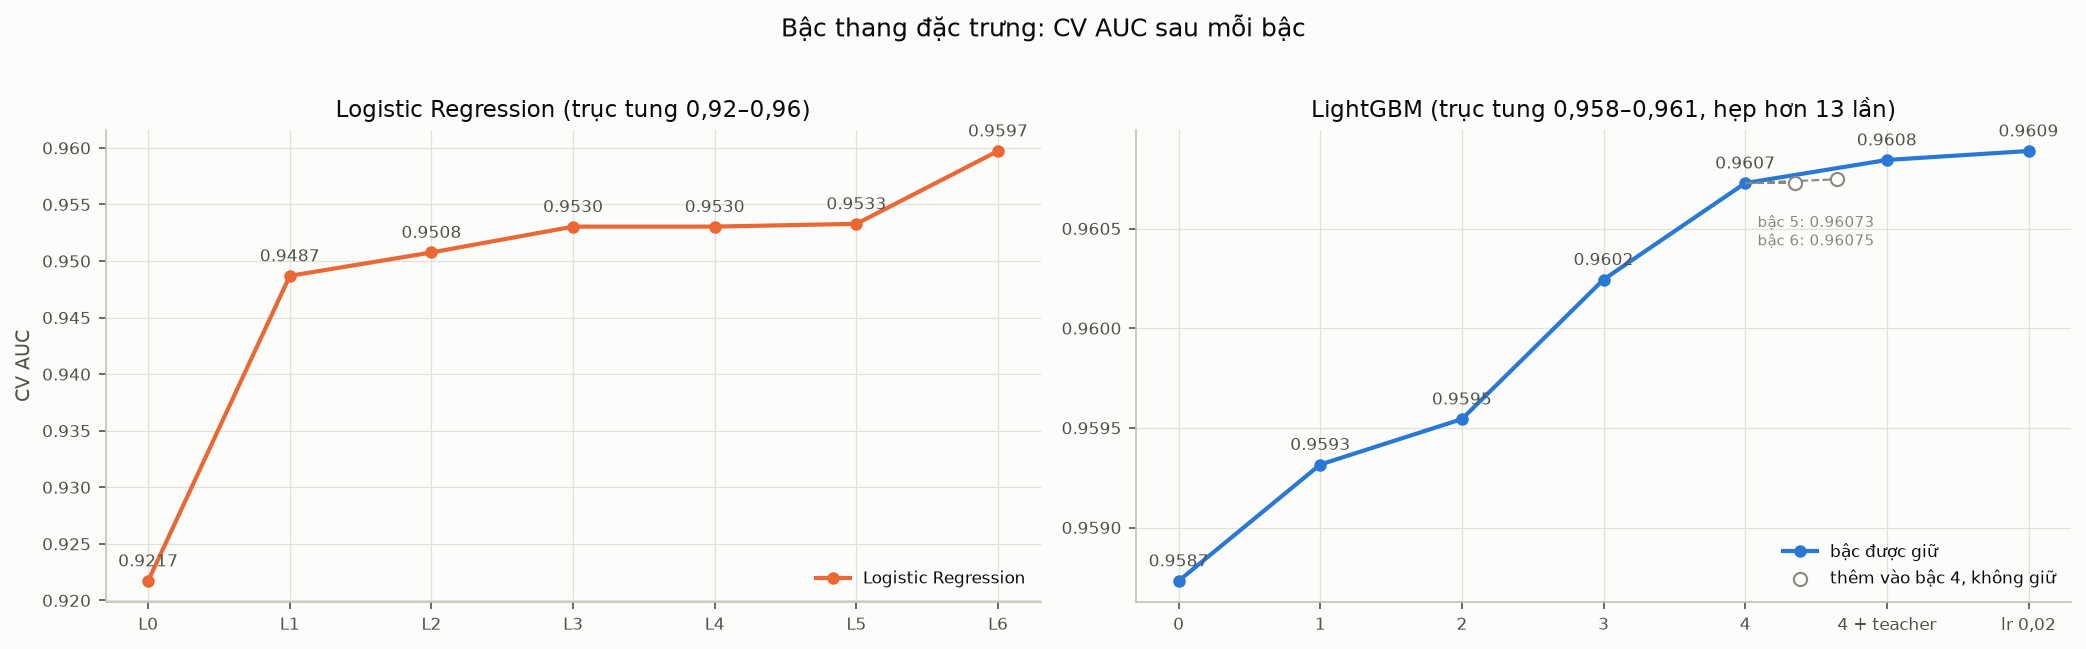

In [13]:
lr_tab = pd.read_csv(RESULTS_DIR / f"{EXP}.csv").set_index("variant")
lr_ladder = lr_tab.loc[[name for name, _, _ in ladder], "cv_auc"]
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2), sharey=False)
ax = axes[0]
ax.plot(range(len(lr_ladder)), lr_ladder.values, color=P.ORANGE, marker="o", label="Logistic Regression")
for i, v in enumerate(lr_ladder.values):
    ax.annotate(f"{v:.4f}", (i, v), textcoords="offset points", xytext=(0, 7), ha="center", fontsize=8, color=P.INK_2)
ax.set_xticks(range(len(lr_ladder)), [s.split(" ", 1)[0] for s in lr_ladder.index])
ax.set_ylabel("CV AUC")
ax.set_title("Logistic Regression (trục tung 0,92–0,96)")
ax.legend(loc="lower right")
if lgb_res is not None:
    g = lgb_res.set_index("variant")["cv_auc"]
    kept = ["0 cột gốc", "1 + chữ số", "2 + tần suất", "3 + TE trong fold", "4 + dữ liệu gốc", "4t + 3 teacher gốc",
            "4t, lr 0,02 (= A_lgb khi thi)"]
    labels = ["0", "1", "2", "3", "4", "4 + teacher", "lr 0,02"]
    ax2 = axes[1]
    ax2.plot(range(len(kept)), g[kept].values, color=P.BLUE, marker="o", label="bậc được giữ")
    for i, v in enumerate(g[kept].values):
        ax2.annotate(f"{v:.4f}", (i, v), textcoords="offset points", xytext=(0, 7), ha="center", fontsize=8, color=P.INK_2)
    for x, name, lab in [(4.35, "5 + tra cứu bộ điểm", "5"), (4.65, "6 + feature nghiệp vụ", "6")]:
        ax2.plot([4, x], [g["4 + dữ liệu gốc"], g[name]], color=P.INK_3, lw=1, ls="--")
        ax2.scatter([x], [g[name]], s=40, facecolors=P.SURFACE, edgecolors=P.INK_3, zorder=3)
    ax2.annotate(f"bậc 5: {g['5 + tra cứu bộ điểm']:.5f}\nbậc 6: {g['6 + feature nghiệp vụ']:.5f}",
                 (4.5, g["5 + tra cứu bộ điểm"]), textcoords="offset points", xytext=(0, -30), ha="center",
                 fontsize=7, color=P.INK_3)
    ax2.scatter([], [], s=40, facecolors=P.SURFACE, edgecolors=P.INK_3, label="thêm vào bậc 4, không giữ")
    ax2.set_xticks(range(len(kept)), labels)
    ax2.set_title("LightGBM (trục tung 0,958–0,961, hẹp hơn 13 lần)")
    ax2.legend(loc="lower right")
fig.suptitle("Bậc thang đặc trưng: CV AUC sau mỗi bậc", y=1.02)
fig.tight_layout()
P.save(fig, "E2_01_ladder")

**Nhận xét mục 5**
- Qua 5 bậc, CV của LightGBM tăng từ 0,95873 lên 0,96084 (+0,0021), mọi bậc được giữ đều tăng ở 5/5 fold. Bậc lớn
  nhất là target encoding trong fold (+7,0×10⁻⁴), sau đó là chữ số (+5,8×10⁻⁴) và dữ liệu gốc (+4,8×10⁻⁴).
- Bậc 5 (tra cứu cả bộ điểm trên dữ liệu gốc, 2/5 fold) và bậc 6 (feature nghiệp vụ như tổng delay, số điểm 0, trung
  bình điểm, 3/5 fold) không làm CV tăng, giống kết luận khi thi. Có thể cây đã tự tách được các feature nghiệp vụ
  này từ cột gốc.
- Về tái lập, bậc cuối (learning rate 0,02) đạt 0,960889 so với 0,960893 của `A_lgb` khi thi (chênh 4×10⁻⁶; chênh
  từng fold có cả âm lẫn dương, trong ±1×10⁻⁴, nhỏ hơn nhiễu giữa hai seed). Learning rate 0,02 cao hơn 0,05 khoảng
  5×10⁻⁵ nhưng cần gấp đôi số cây.
- Mọi nhánh tiền xử lý đều chỉ làm CV thay đổi trong ±5×10⁻⁵ và không nhất quán giữa các fold. Cây chia nhánh theo
  thứ tự giá trị nên không nhạy với log1p, chuẩn hoá hay cắt ngưỡng; LightGBM tự xử lý giá trị thiếu; cách mã hoá
  category cũng gần như không ảnh hưởng.
- Bảng "cùng một bước, hai model" cho thấy cùng một bước có tác dụng rất khác nhau. Mã hoá điểm thành biến phân loại
  tăng 0,027 với LR nhưng giảm 4×10⁻⁵ với LightGBM; log1p tăng 1,7×10⁻⁴ với LR nhưng giảm 1×10⁻⁵ với LightGBM. Ngược
  lại, chữ số và tần suất tăng 8×10⁻⁴ với LightGBM nhưng gần như 0 với LR.

## 6. Tóm tắt và quyết định

| | Logistic Regression | LightGBM |
| --- | --- | --- |
| Baseline → bộ đầy đủ | 0,9217 → 0,9597 (+0,038) | 0,9587 → 0,9609 (+0,002) |
| Bước quan trọng nhất | mã hoá điểm one-hot (+0,027), dữ liệu gốc (+0,006) | TE trong fold, chữ số, dữ liệu gốc (+0,0005–0,0007 mỗi bước) |
| Điền thiếu, log1p, chuẩn hoá, cắt ngoại lệ | log1p có ích; chuẩn hoá chỉ làm nhanh hơn ×43 | không tác dụng (±5×10⁻⁵) |
| Tái lập model khi thi | 0,959727 so với 0,959737 | 0,960889 so với 0,960893 |

**Quyết định:**
1. Tiền xử lý tuỳ theo loại model. Model tuyến tính và mạng nơ-ron dùng dạng L1 (one-hot điểm và category, log1p
   delay, z-score); model cây dùng 21 cột gốc, category để kiểu `category`. Áp dụng ở E3.
2. Bộ feature đầy đủ của LightGBM = bậc 4 + teacher (`src/features.py`, step 4, teachers=True).
3. Không xoá dòng ngoại lệ, không cần imputer phức tạp; chọn feature bằng CV, không bằng AUC một cột.

**Đã thử nhưng không giữ**

| Ý tưởng | Thời điểm | Δ CV | Số fold tăng | Lý do không giữ |
| --- | --- | --- | --- | --- |
| Ghép 129 nghìn dòng dữ liệu gốc vào phần train của fold (LightGBM) | 18/10 | +1×10⁻⁴ (model đơn), 0 khi vào stack | – | lợi ích nhỏ, không thêm thông tin cho stack |
| Ghép dòng gốc với trọng số 0,35 (XGBoost của nhóm) | 17/10 | 0,95853, thấp hơn bản dùng teacher (0,96094) | – | teacher tốt hơn ghép dòng |
| LightGBM bậc 5: tra cứu bộ điểm trên dữ liệu gốc | 14/10, kiểm chứng | +1×10⁻⁶ | 2/5 | dưới nhiễu |
| LightGBM bậc 6: feature nghiệp vụ | 14/10, kiểm chứng | +1,8×10⁻⁵ | 3/5 | dưới nhiễu |
| LR: chữ số, tần suất (L4) | kiểm chứng | +3×10⁻⁶ | 3/5 | không có tác dụng với model tuyến tính |
| LR: tổng hợp điểm, KMeans, PCA trên bộ đầy đủ | kiểm chứng | +2,8×10⁻⁵ | 5/5 | quá nhỏ, thông tin đã có sẵn |
| LR: PCA 5 thành phần | kiểm chứng | ≈ 0 | 3/5 | biến đổi tuyến tính, LR tự làm được |
| Mọi nhánh điền thiếu, cắt ngoại lệ, chuẩn hoá (cả hai model) | kiểm chứng | ±5×10⁻⁵ | không nhất quán | dữ liệu thiếu rất ít; cây không nhạy |
| Bỏ 5 cột yếu nhất theo AUC một cột | kiểm chứng | −0,0014 | 0/5 | cột yếu riêng lẻ vẫn có ích khi kết hợp |
| Teacher xử lý chỗ lệch delay: bỏ hai cột delay, chỉ dùng dòng gốc có delay = 0, hoặc đặt trọng số theo adversarial validation (`A_orig_teacher.py`) | 15/10 | AUC của teacher tăng từ 0,95441 lên 0,95459–0,95471; vào stacking giảm 1×10⁻⁶ đến 5×10⁻⁶ | – | teacher tốt hơn khi đứng riêng nhưng không thêm thông tin cho stacking |